# Sale Performance Dashboard — Analysis Notebook
**Author:** Tawananyasha Nigel Chinembiri  ·  **Dataset:** `data/ecommerce_orders.csv` (1,200 orders, Jan 2023 – Jun 2025)

This notebook analyses sales performance and **saves every chart as a PNG in `images/`**. The Streamlit app (`app.py`) presents the same findings interactively.

### Business definitions (used consistently everywhere)
| Metric | Definition |
|---|---|
| **Gross Sales** | `TotalPrice` summed over all orders placed |
| **Lost Revenue** | `TotalPrice` of orders with status *Cancelled* or *Returned* |
| **Net Revenue** | Gross Sales − Lost Revenue (Pending + Shipped + Delivered orders) |
| **Loss Rate** | Share of orders that were Cancelled or Returned |
| **AOV** | Average order value |

## 0. Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sales_utils import (load_orders, validate_orders, kpis, group_summary, monthly_summary,
                         h1_comparison, chi_square_loss, STATUS_ORDER, DOW_LABELS)

warnings.filterwarnings("ignore")
IMG_DIR = Path("images");  IMG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# Colour-blind-safe palette with fixed meanings across every chart
NET, LOST, GROSS = "#0072B2", "#D55E00", "#8C8C8C"
ACCENT, SOFT = "#E69F00", "#56B4E9"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.titleweight": "bold", "axes.titlesize": 13,
                                     "axes.grid.axis": "y", "figure.dpi": 110, "savefig.dpi": 160})
money = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")
money_k = mtick.FuncFormatter(lambda x, _: f"${x/1000:,.0f}k")
pct = mtick.PercentFormatter(1.0, decimals=0)

def save(fig, name):
    path = IMG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved ->", path)

## 1. Load, validate and prepare the data

In [2]:
df = load_orders("data/ecommerce_orders.csv")
checks = validate_orders(df)
pd.Series(checks, name="value").to_frame()

,value
rows,1200
duplicate_order_ids,0
null_cells_excl_coupon,0
max_abs_total_price_error,0.0
non_positive_prices_or_qty,0
date_min,2023-01-01
date_max,2025-06-30


In [3]:
df[["OrderID","Date","Product","Quantity","UnitPrice","TotalPrice","OrderStatus","CouponCode","NetRevenue","LostRevenue"]].head()

,OrderID,Date,Product,Quantity,UnitPrice,TotalPrice,OrderStatus,CouponCode,NetRevenue,LostRevenue
0,ORD200000,2023-01-04,Monitor,5,570.62,2853.10,Shipped,SAVE10,2853.10,0.00
1,ORD200001,2024-08-23,Phone,2,151.35,302.70,Shipped,SAVE10,302.70,0.00
2,ORD200002,2024-02-27,Tablet,5,550.68,2753.40,Cancelled,FREESHIP,0.00,2753.40
3,ORD200003,2023-10-15,Chair,1,273.19,273.19,Returned,SAVE10,0.00,273.19
4,ORD200004,2025-05-08,Printer,4,626.01,2504.04,Delivered,SAVE10,2504.04,0.00


## 2. Headline KPIs

In [4]:
K = kpis(df)
kpi_table = pd.DataFrame({
    "Metric": ["Orders","Gross Sales","Net Revenue","Lost Revenue","Loss Rate","Cancel Rate","Return Rate",
               "Units Sold (net)","AOV (all orders)","AOV (net orders)","Unique Customers","Orders with Coupon"],
    "Value": [f"{K['orders']:,}", f"${K['gross']:,.2f}", f"${K['net']:,.2f}", f"${K['lost']:,.2f}",
              f"{K['loss_rate']:.1%}", f"{K['cancel_rate']:.1%}", f"{K['return_rate']:.1%}",
              f"{K['units']:,}", f"${K['aov_gross']:,.2f}", f"${K['aov_net']:,.2f}",
              f"{K['customers']:,}", f"{K['coupon_share']:.1%}"]})
kpi_table

,Metric,Value
0,Orders,"1,200"
1,Gross Sales,"$1,264,761.96"
2,Net Revenue,"$745,088.05"
3,Lost Revenue,"$519,673.91"
4,Loss Rate,41.4%
5,Cancel Rate,20.8%
6,Return Rate,20.6%
7,Units Sold (net),"2,094"
8,AOV (all orders),"$1,053.97"
9,AOV (net orders),"$1,059.87"


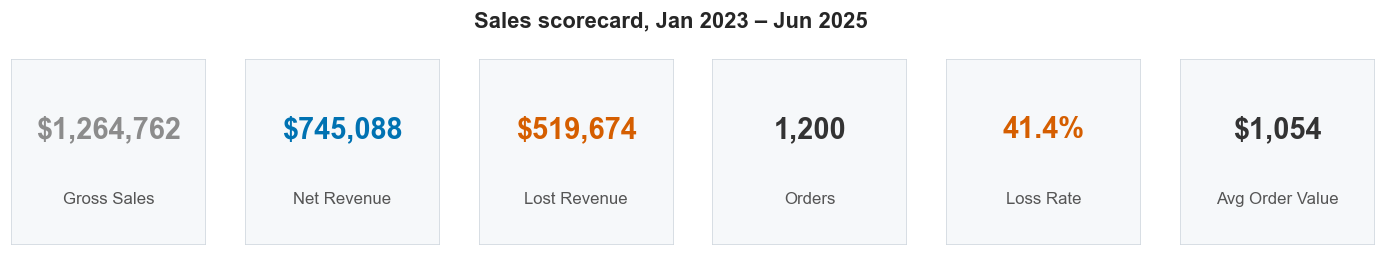

saved -> images\00_kpi_scorecard.png


In [5]:
# Image 00: KPI scorecard
tiles = [("Gross Sales", f"${K['gross']:,.0f}", GROSS), ("Net Revenue", f"${K['net']:,.0f}", NET),
         ("Lost Revenue", f"${K['lost']:,.0f}", LOST), ("Orders", f"{K['orders']:,}", "#333333"),
         ("Loss Rate", f"{K['loss_rate']:.1%}", LOST), ("Avg Order Value", f"${K['aov_gross']:,.0f}", "#333333")]
fig, axes = plt.subplots(1, 6, figsize=(16, 2.2))
for ax, (lab, val, col) in zip(axes, tiles):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fc="#F6F8FA", ec="#D0D7DE", lw=1))
    ax.text(0.5, 0.62, val, ha="center", va="center", fontsize=19, fontweight="bold", color=col, transform=ax.transAxes)
    ax.text(0.5, 0.25, lab, ha="center", va="center", fontsize=11, color="#555555", transform=ax.transAxes)
fig.suptitle("Sales scorecard, Jan 2023 – Jun 2025", fontweight="bold", y=1.08)
save(fig, "00_kpi_scorecard")

## 3. Sales over time

### 3.1 Monthly revenue trend
Net revenue per month with a 3-month moving average, against gross sales for context.

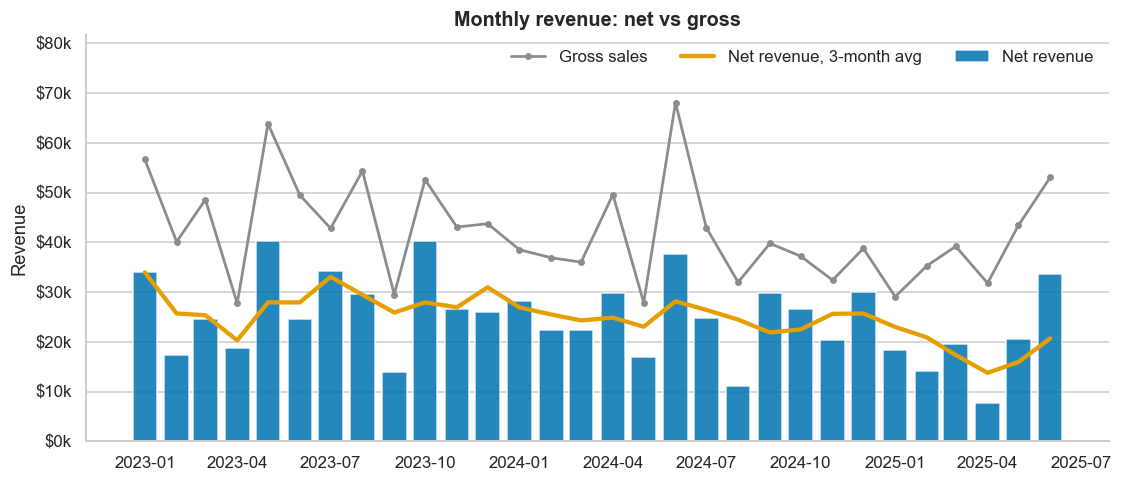

saved -> images\01_monthly_revenue_trend.png


,YearMonth,Orders,GrossSales,NetRevenue,LostRevenue,NetRevenue_MA3
24,2025-01-01,27,29099.40,18424.28,10675.12,23009.36
25,2025-02-01,37,35317.55,14167.80,21149.75,20908.15
26,2025-03-01,49,39200.66,19502.47,19698.19,17364.85
27,2025-04-01,32,31821.20,7708.18,24113.02,13792.82
28,2025-05-01,37,43396.64,20669.68,22726.96,15960.11
29,2025-06-01,49,53047.40,33727.98,19319.42,20701.95


In [6]:
monthly = monthly_summary(df)
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(monthly["YearMonth"], monthly["NetRevenue"], width=24, color=NET, alpha=.85, label="Net revenue")
ax.plot(monthly["YearMonth"], monthly["GrossSales"], color=GROSS, lw=1.8, marker="o", ms=3.5, label="Gross sales")
ax.plot(monthly["YearMonth"], monthly["NetRevenue_MA3"], color=ACCENT, lw=2.8, label="Net revenue, 3-month avg")
ax.yaxis.set_major_formatter(money_k)
ax.set_title("Monthly revenue: net vs gross"); ax.set_xlabel(""); ax.set_ylabel("Revenue")
ax.legend(frameon=False, ncol=3, loc="upper right"); ax.set_ylim(0, monthly["GrossSales"].max()*1.2)
save(fig, "01_monthly_revenue_trend")
monthly.round(2).tail(6)

### 3.2 Like-for-like growth: H1 2023 vs H1 2024 vs H1 2025
The dataset stops on 30 Jun 2025, so full-year totals would make 2025 look artificially weak. Comparing Jan–Jun only is the fair view.

,Year,Orders,GrossSales,NetRevenue,LostRevenue,GrossChange,NetChange,LossRate_Rev
0,2023,252,286501.52,159930.12,126571.40,NaN,NaN,0.442
1,2024,237,257059.34,157461.74,99597.60,-0.103,-0.015,0.387
2,2025,231,231882.85,114200.39,117682.46,-0.098,-0.275,0.508


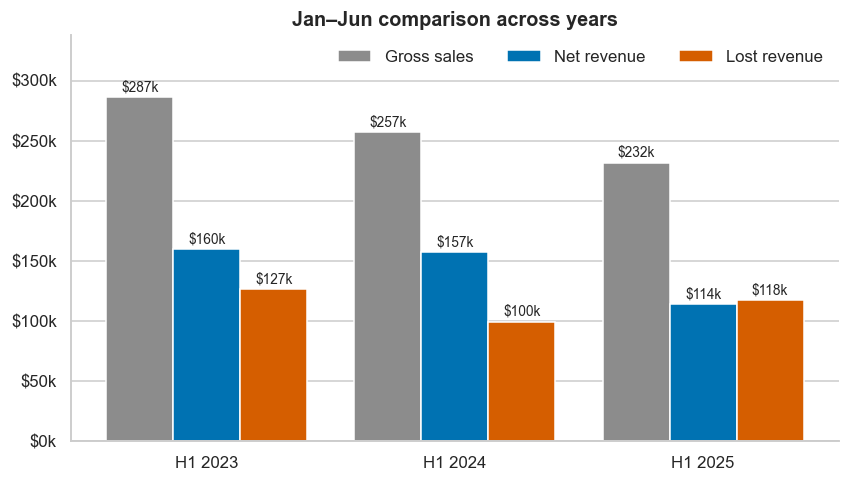

saved -> images\02_h1_year_over_year.png


In [7]:
h1 = h1_comparison(df)
h1["GrossChange"] = h1["GrossSales"].pct_change()
h1["NetChange"] = h1["NetRevenue"].pct_change()
h1["LossRate_Rev"] = h1["LostRevenue"] / h1["GrossSales"]
display(h1.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(h1)); w = 0.27
for i, (col, c, lab) in enumerate([("GrossSales", GROSS, "Gross sales"), ("NetRevenue", NET, "Net revenue"), ("LostRevenue", LOST, "Lost revenue")]):
    bars = ax.bar(x + (i-1)*w, h1[col], w, color=c, label=lab)
    ax.bar_label(bars, labels=[f"${v/1000:,.0f}k" for v in h1[col]], padding=2, fontsize=9)
ax.set_xticks(x, [f"H1 {y}" for y in h1["Year"]]); ax.yaxis.set_major_formatter(money_k)
ax.set_title("Jan–Jun comparison across years"); ax.legend(frameon=False, ncol=3, loc="upper right")
ax.set_ylim(0, h1["GrossSales"].max()*1.18)
save(fig, "02_h1_year_over_year")

### 3.3 Quarterly revenue split into kept vs lost

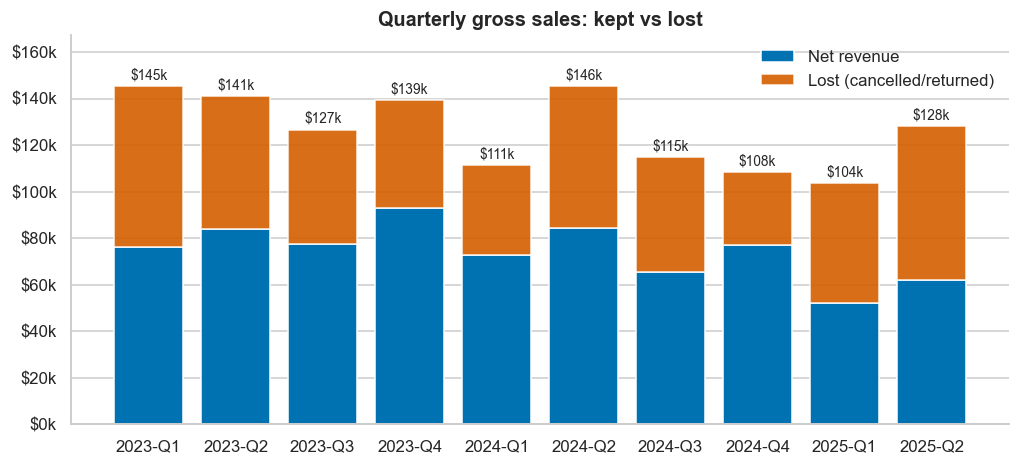

saved -> images\03_quarterly_revenue.png


In [8]:
q = df.groupby("YearQuarter").agg(Net=("NetRevenue","sum"), Lost=("LostRevenue","sum")).reset_index()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(q["YearQuarter"], q["Net"], color=NET, label="Net revenue")
ax.bar(q["YearQuarter"], q["Lost"], bottom=q["Net"], color=LOST, alpha=.9, label="Lost (cancelled/returned)")
for i, r in q.iterrows():
    ax.text(i, r["Net"]+r["Lost"]+3000, f"${(r['Net']+r['Lost'])/1000:,.0f}k", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(money_k); ax.set_title("Quarterly gross sales: kept vs lost"); ax.set_xlabel("")
ax.legend(frameon=False, loc="upper right"); ax.set_ylim(0, (q["Net"]+q["Lost"]).max()*1.15)
save(fig, "03_quarterly_revenue")

## 4. Product performance

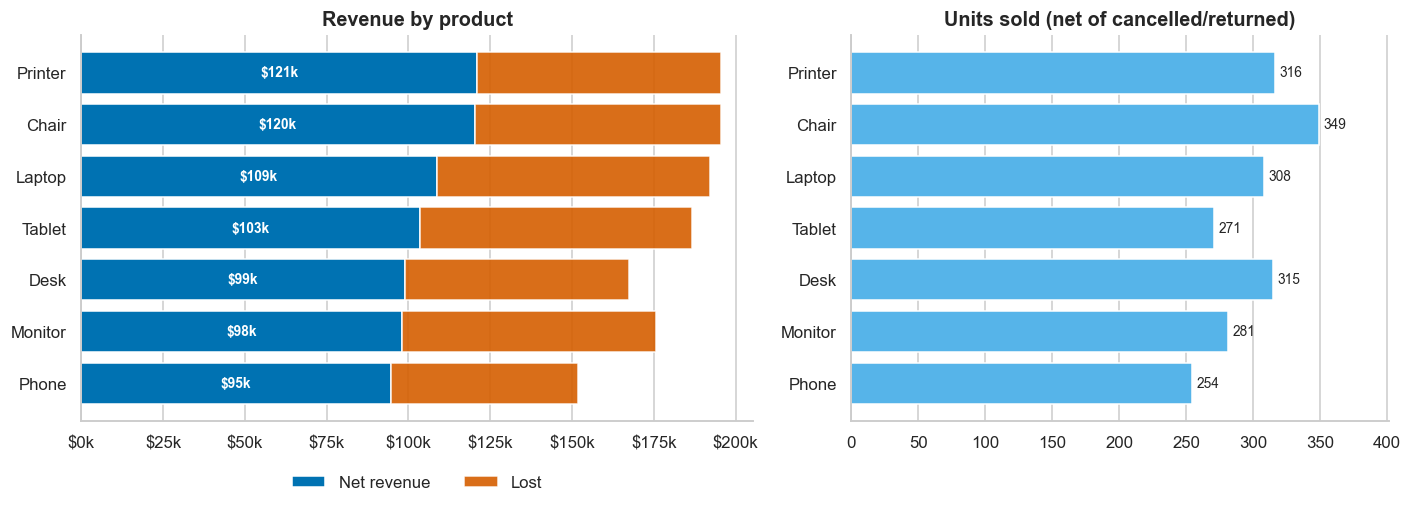

saved -> images\04_product_revenue_units.png


,Product,Orders,GrossSales,NetRevenue,LostRevenue,UnitsSold,LossRate,AvgOrderValue,NetShare
5,Printer,181,195612.61,120998.36,74614.25,316,0.403,1080.733,0.162
0,Chair,178,195620.11,120320.97,75299.14,349,0.410,1098.989,0.161
2,Laptop,173,192126.56,108710.54,83416.02,308,0.428,1110.558,0.146
6,Tablet,179,186568.95,103413.13,83155.82,271,0.430,1042.285,0.139
1,Desk,170,167459.93,99040.75,68419.18,315,0.394,985.058,0.133
3,Monitor,163,175651.41,98069.37,77582.04,281,0.436,1077.616,0.132
4,Phone,156,151722.39,94534.93,57187.46,254,0.397,972.579,0.127


In [9]:
prod = group_summary(df, "Product").sort_values("NetRevenue", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.barh(prod["Product"], prod["NetRevenue"], color=NET, label="Net revenue")
ax.barh(prod["Product"], prod["LostRevenue"], left=prod["NetRevenue"], color=LOST, alpha=.9, label="Lost")
for i, r in enumerate(prod.itertuples()):
    ax.text(r.NetRevenue/2, i, f"${r.NetRevenue/1000:,.0f}k", va="center", ha="center", color="white", fontsize=9, fontweight="bold")
ax.xaxis.set_major_formatter(money_k); ax.set_title("Revenue by product"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); ax.grid(False); ax.grid(axis="x")
ax = axes[1]
ax.barh(prod["Product"], prod["UnitsSold"], color=SOFT)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set_title("Units sold (net of cancelled/returned)"); ax.set_xlim(0, prod["UnitsSold"].max()*1.15); ax.grid(False); ax.grid(axis="x")
fig.tight_layout()
save(fig, "04_product_revenue_units")
prod.sort_values("NetRevenue", ascending=False).round(3)

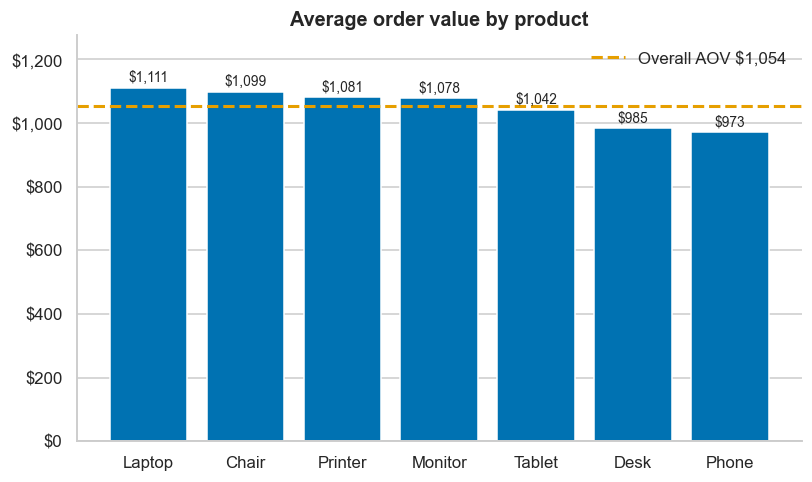

saved -> images\05_product_aov.png


In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
p2 = group_summary(df, "Product").sort_values("AvgOrderValue", ascending=False)
bars = ax.bar(p2["Product"], p2["AvgOrderValue"], color=NET)
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in p2["AvgOrderValue"]], padding=2, fontsize=9)
ax.axhline(df["TotalPrice"].mean(), color=ACCENT, lw=2, ls="--", label=f"Overall AOV ${df['TotalPrice'].mean():,.0f}")
ax.yaxis.set_major_formatter(money); ax.set_title("Average order value by product"); ax.legend(frameon=False)
ax.set_ylim(0, p2["AvgOrderValue"].max()*1.15)
save(fig, "05_product_aov")

## 5. Order status and revenue at risk

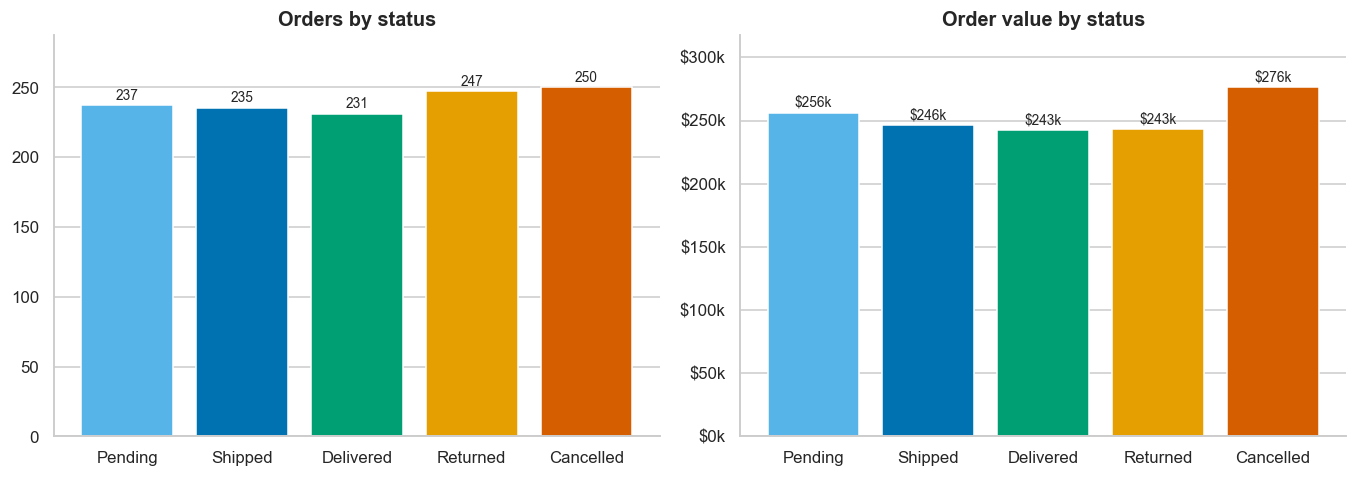

saved -> images\06_order_status.png


,OrderStatus,Orders,Value,Share
0,Pending,237,256328.15,0.198
1,Shipped,235,246159.58,0.196
2,Delivered,231,242600.32,0.192
3,Returned,247,243277.70,0.206
4,Cancelled,250,276396.21,0.208


In [11]:
st = df.groupby("OrderStatus").agg(Orders=("OrderID","count"), Value=("TotalPrice","sum")).reindex(STATUS_ORDER).reset_index()
colors = [SOFT, "#009E73", "#009E73", LOST, LOST]
colors = {"Pending": SOFT, "Shipped": NET, "Delivered": "#009E73", "Returned": ACCENT, "Cancelled": LOST}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for ax, col, title, fmt in [(axes[0], "Orders", "Orders by status", None), (axes[1], "Value", "Order value by status", money_k)]:
    bars = ax.bar(st["OrderStatus"], st[col], color=[colors[s] for s in st["OrderStatus"]])
    ax.bar_label(bars, labels=[f"{v:,.0f}" if col == "Orders" else f"${v/1000:,.0f}k" for v in st[col]], padding=2, fontsize=9)
    ax.set_title(title); ax.set_ylim(0, st[col].max()*1.15)
    if fmt: ax.yaxis.set_major_formatter(fmt)
fig.tight_layout()
save(fig, "06_order_status")
st.assign(Share=lambda d: d["Orders"]/d["Orders"].sum()).round(3)

### 5.1 Where do cancellations and returns concentrate?
Overall, **41%** of orders are lost. Before naming a "problem" segment, we test whether differences between segments are bigger than random variation (chi-square test of independence; bars show 95% confidence intervals).

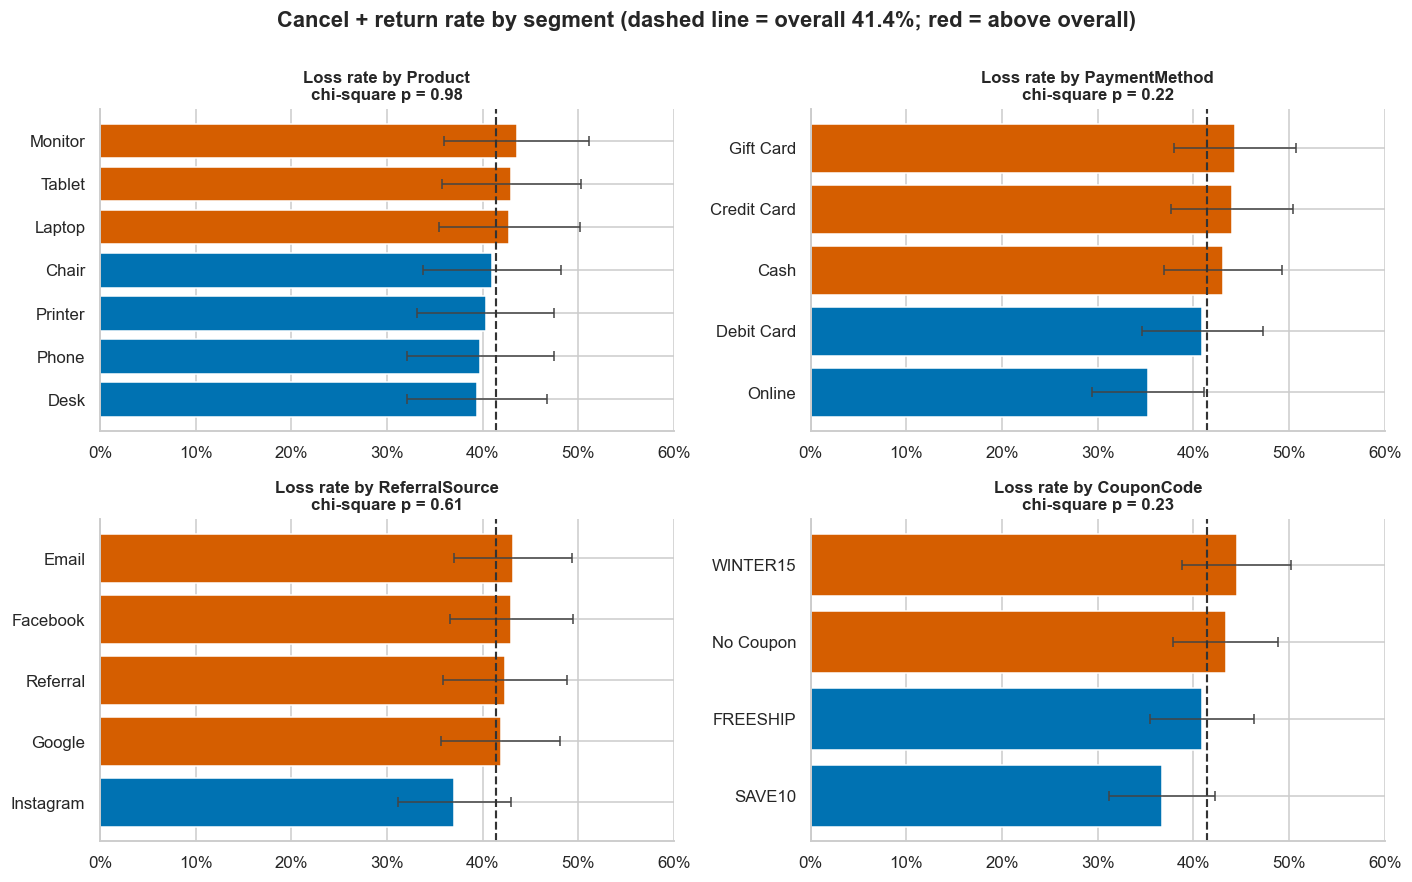

saved -> images\07_loss_rate_by_segment.png


,Dimension,chi2,p_value,Significant (p<0.05)
0,Product,1.19,0.9774,False
1,PaymentMethod,5.79,0.2156,False
2,ReferralSource,2.68,0.6125,False
3,CouponCode,4.29,0.2322,False


In [12]:
dims = ["Product", "PaymentMethod", "ReferralSource", "CouponCode"]
overall = df["IsLost"].mean()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
tests = []
for ax, d in zip(axes.ravel(), dims):
    g = df.groupby(d)["IsLost"].agg(["mean", "count"]).sort_values("mean")
    ci = 1.96 * np.sqrt(g["mean"]*(1-g["mean"])/g["count"])
    chi2, p = chi_square_loss(df, d); tests.append({"Dimension": d, "chi2": round(chi2, 2), "p_value": round(p, 4), "Significant (p<0.05)": p < 0.05})
    ax.barh(g.index, g["mean"], xerr=ci, color=[LOST if v > overall else NET for v in g["mean"]], error_kw=dict(ecolor="#444", lw=1, capsize=3))
    ax.axvline(overall, color="#333", ls="--", lw=1.4); ax.grid(axis="x")
    ax.set_xlim(0, 0.6); ax.xaxis.set_major_formatter(pct)
    ax.set_title(f"Loss rate by {d}\nchi-square p = {p:.2f}", fontsize=11)
fig.suptitle(f"Cancel + return rate by segment (dashed line = overall {overall:.1%}; red = above overall)", fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "07_loss_rate_by_segment")
pd.DataFrame(tests)

## 6. Marketing: referral source and coupons

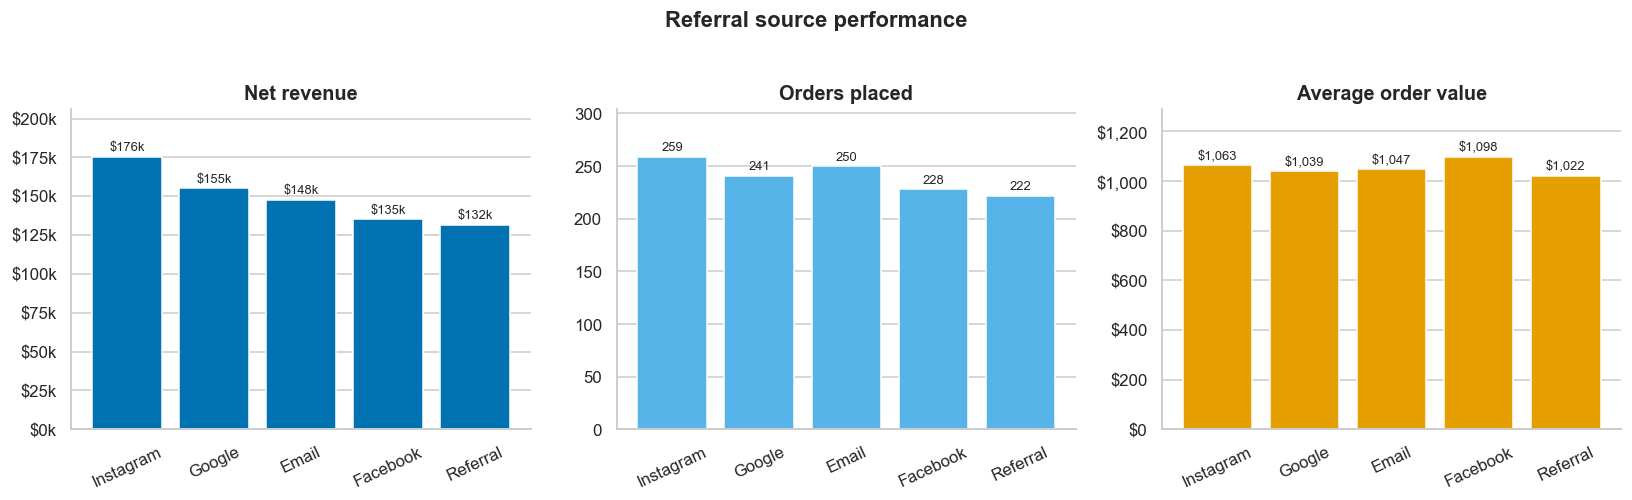

saved -> images\08_referral_source.png


,ReferralSource,Orders,GrossSales,NetRevenue,LostRevenue,UnitsSold,LossRate,AvgOrderValue,NetShare
3,Instagram,259,275285.45,175505.50,99779.95,492,0.371,1062.878,0.236
2,Google,241,250441.48,155085.42,95356.06,430,0.419,1039.176,0.208
0,Email,250,261808.55,147787.01,114021.54,423,0.432,1047.234,0.198
1,Facebook,228,250410.90,135116.78,115294.12,378,0.430,1098.293,0.181
4,Referral,222,226815.58,131593.34,95222.24,371,0.423,1021.692,0.177


In [13]:
ref = group_summary(df, "ReferralSource").sort_values("NetRevenue", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[0].bar(ref["ReferralSource"], ref["NetRevenue"], color=NET); axes[0].yaxis.set_major_formatter(money_k); axes[0].set_title("Net revenue")
axes[1].bar(ref["ReferralSource"], ref["Orders"], color=SOFT); axes[1].set_title("Orders placed")
axes[2].bar(ref["ReferralSource"], ref["AvgOrderValue"], color=ACCENT); axes[2].yaxis.set_major_formatter(money); axes[2].set_title("Average order value")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.bar_label(ax.containers[0], labels=[(f"${b.get_height()/1000:,.0f}k" if ax is axes[0] else f"${b.get_height():,.0f}" if ax is axes[2] else f"{b.get_height():,.0f}") for b in ax.containers[0]], padding=2, fontsize=8.5)
    ax.set_ylim(0, ax.get_ylim()[1]*1.12)
fig.suptitle("Referral source performance", fontweight="bold", y=1.03); fig.tight_layout()
save(fig, "08_referral_source")
ref.round(3)

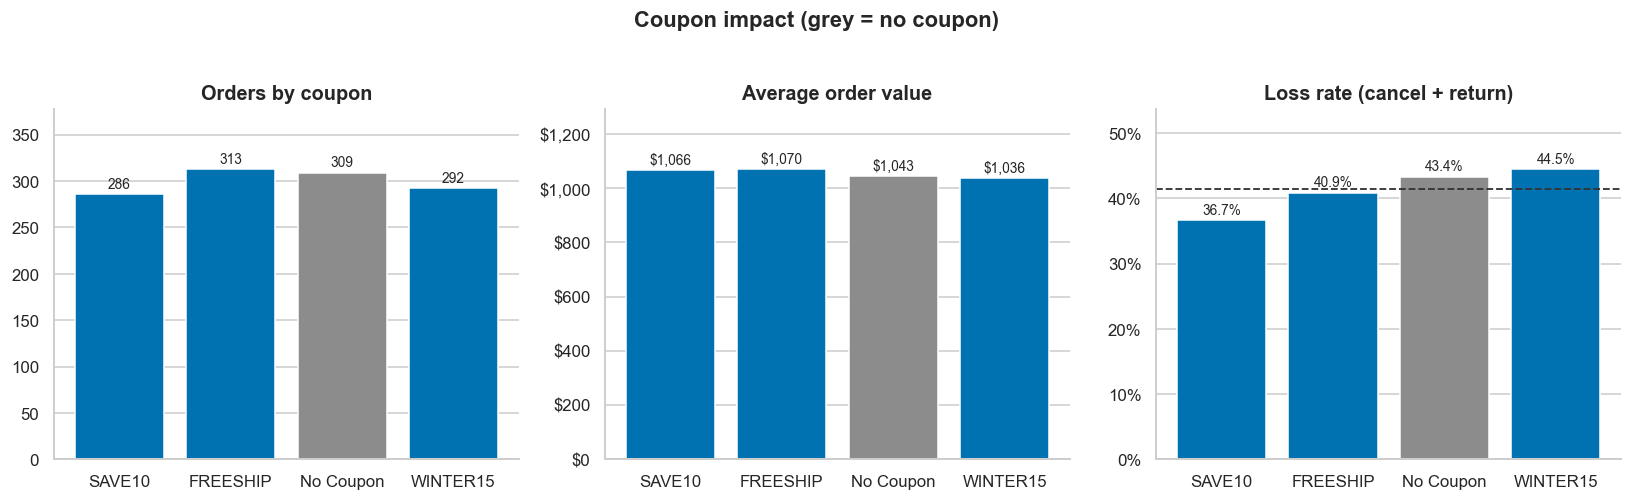

saved -> images\09_coupon_impact.png


,CouponCode,Orders,GrossSales,NetRevenue,LostRevenue,UnitsSold,LossRate,AvgOrderValue,NetShare
2,SAVE10,286,304840.02,203007.56,101832.46,566,0.367,1065.874,0.272
0,FREESHIP,313,335036.99,196107.89,138929.10,533,0.409,1070.406,0.263
1,No Coupon,309,322401.41,185344.29,137057.12,541,0.434,1043.370,0.249
3,WINTER15,292,302483.54,160628.31,141855.23,454,0.445,1035.903,0.216


In [14]:
cp = group_summary(df, "CouponCode").sort_values("NetRevenue", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
bars = axes[0].bar(cp["CouponCode"], cp["Orders"], color=[GROSS if c == "No Coupon" else NET for c in cp["CouponCode"]])
axes[0].bar_label(bars, padding=2, fontsize=9); axes[0].set_title("Orders by coupon")
bars = axes[1].bar(cp["CouponCode"], cp["AvgOrderValue"], color=[GROSS if c == "No Coupon" else NET for c in cp["CouponCode"]])
axes[1].bar_label(bars, labels=[f"${v:,.0f}" for v in cp["AvgOrderValue"]], padding=2, fontsize=9); axes[1].set_title("Average order value"); axes[1].yaxis.set_major_formatter(money)
bars = axes[2].bar(cp["CouponCode"], cp["LossRate"], color=[GROSS if c == "No Coupon" else NET for c in cp["CouponCode"]])
axes[2].bar_label(bars, labels=[f"{v:.1%}" for v in cp["LossRate"]], padding=2, fontsize=9); axes[2].set_title("Loss rate (cancel + return)"); axes[2].yaxis.set_major_formatter(pct)
axes[2].axhline(overall, color="#333", ls="--", lw=1.2)
for ax in axes:
    ax.set_ylim(0, ax.get_ylim()[1]*1.15)
fig.suptitle("Coupon impact (grey = no coupon)", fontweight="bold", y=1.03); fig.tight_layout()
save(fig, "09_coupon_impact")
cp.round(3)

## 7. Payment method and timing

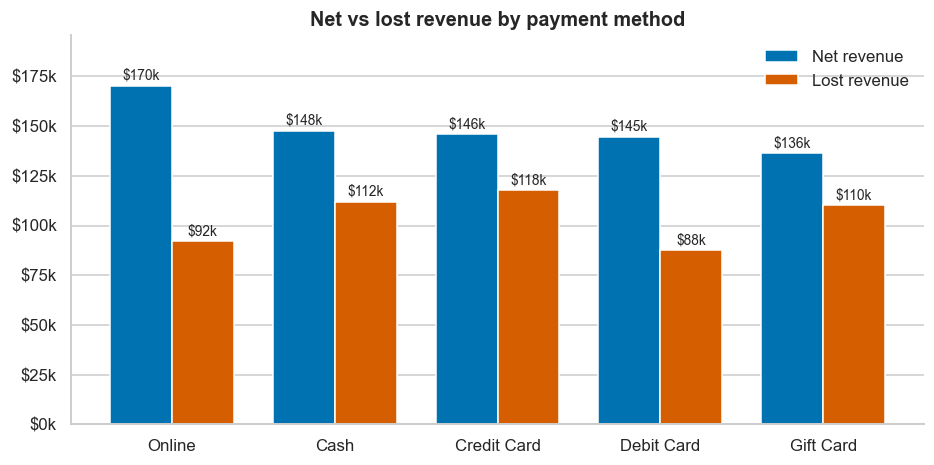

saved -> images\10_payment_method.png


,PaymentMethod,Orders,GrossSales,NetRevenue,LostRevenue,UnitsSold,LossRate,AvgOrderValue,NetShare
4,Online,258,262442.94,170273.44,92169.50,475,0.353,1017.221,0.229
0,Cash,246,259786.29,147733.44,112052.85,435,0.431,1056.042,0.198
1,Credit Card,234,263847.63,146114.38,117733.25,400,0.440,1127.554,0.196
2,Debit Card,232,232361.18,144727.62,87633.56,397,0.409,1001.557,0.194
3,Gift Card,230,246323.92,136239.17,110084.75,387,0.443,1070.974,0.183


In [15]:
pay = group_summary(df, "PaymentMethod").sort_values("NetRevenue", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(pay)); w = 0.38
b1 = ax.bar(x - w/2, pay["NetRevenue"], w, color=NET, label="Net revenue")
b2 = ax.bar(x + w/2, pay["LostRevenue"], w, color=LOST, label="Lost revenue")
ax.bar_label(b1, labels=[f"${v/1000:,.0f}k" for v in pay["NetRevenue"]], padding=2, fontsize=9)
ax.bar_label(b2, labels=[f"${v/1000:,.0f}k" for v in pay["LostRevenue"]], padding=2, fontsize=9)
ax.set_xticks(x, pay["PaymentMethod"]); ax.yaxis.set_major_formatter(money_k); ax.set_title("Net vs lost revenue by payment method")
ax.legend(frameon=False); ax.set_ylim(0, max(pay["NetRevenue"].max(), pay["LostRevenue"].max())*1.15)
save(fig, "10_payment_method")
pay.round(3)

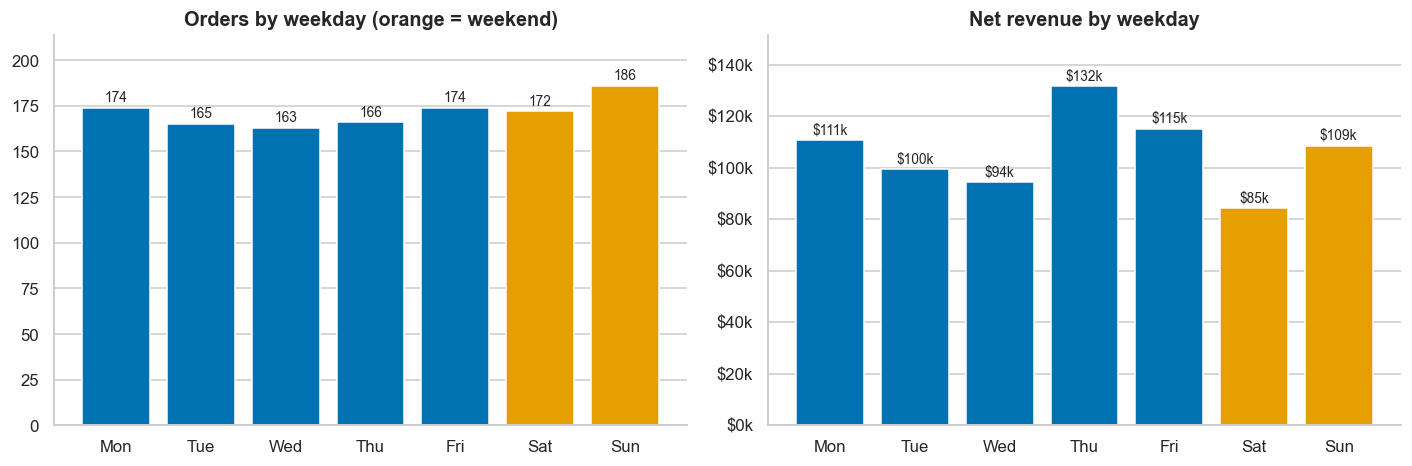

saved -> images\11_day_of_week.png


In [16]:
dow = group_summary(df, "DayName").set_index("DayName").reindex(DOW_LABELS).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
bars = axes[0].bar(dow["DayName"], dow["Orders"], color=[ACCENT if d in ("Sat","Sun") else NET for d in dow["DayName"]])
axes[0].bar_label(bars, padding=2, fontsize=9); axes[0].set_title("Orders by weekday (orange = weekend)"); axes[0].set_ylim(0, dow["Orders"].max()*1.15)
bars = axes[1].bar(dow["DayName"], dow["NetRevenue"], color=[ACCENT if d in ("Sat","Sun") else NET for d in dow["DayName"]])
axes[1].bar_label(bars, labels=[f"${v/1000:,.0f}k" for v in dow["NetRevenue"]], padding=2, fontsize=9)
axes[1].yaxis.set_major_formatter(money_k); axes[1].set_title("Net revenue by weekday"); axes[1].set_ylim(0, dow["NetRevenue"].max()*1.15)
fig.tight_layout()
save(fig, "11_day_of_week")

## 8. Heatmaps

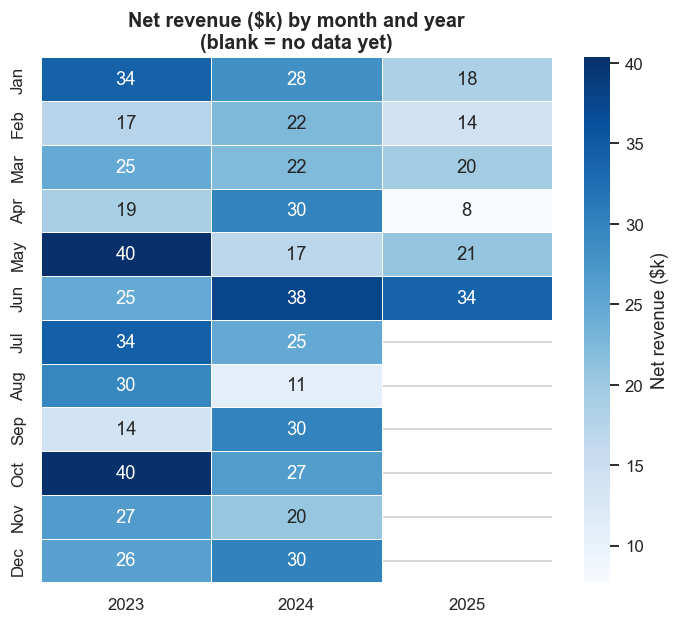

saved -> images\12_heatmap_month_year.png


In [17]:
pv = df.pivot_table(index="Month", columns="Year", values="NetRevenue", aggfunc="sum")
pv.loc[pv.index > 6, 2025] = np.nan      # data ends 30 Jun 2025: show Jul-Dec 2025 as blank, not zero
pv.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(pv/1000, annot=True, fmt=".0f", cmap="Blues", linewidths=.5, linecolor="white", cbar_kws={"label": "Net revenue ($k)"}, ax=ax)
ax.set_title("Net revenue ($k) by month and year\n(blank = no data yet)"); ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "12_heatmap_month_year")

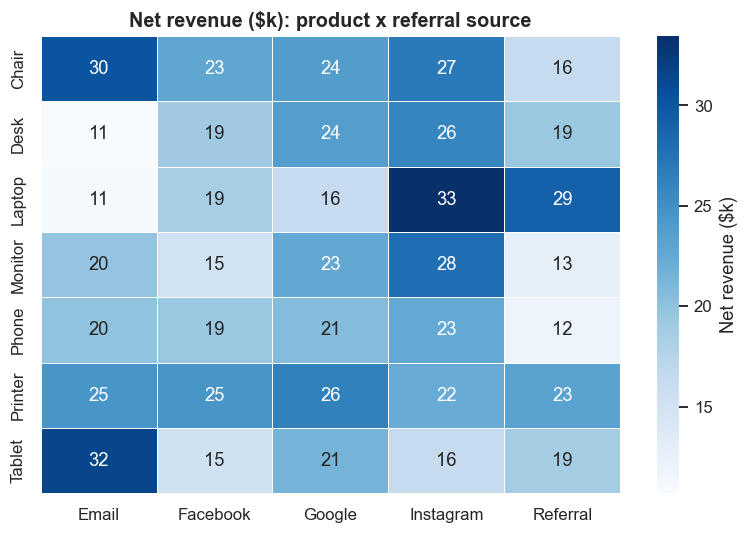

saved -> images\13_heatmap_product_referral.png


In [18]:
pp = df.pivot_table(index="Product", columns="ReferralSource", values="NetRevenue", aggfunc="sum")
fig, ax = plt.subplots(figsize=(8.5, 5.4))
sns.heatmap(pp/1000, annot=True, fmt=".0f", cmap="Blues", linewidths=.5, linecolor="white", cbar_kws={"label": "Net revenue ($k)"}, ax=ax)
ax.set_title("Net revenue ($k): product x referral source"); ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "13_heatmap_product_referral")

## 9. Order value distribution

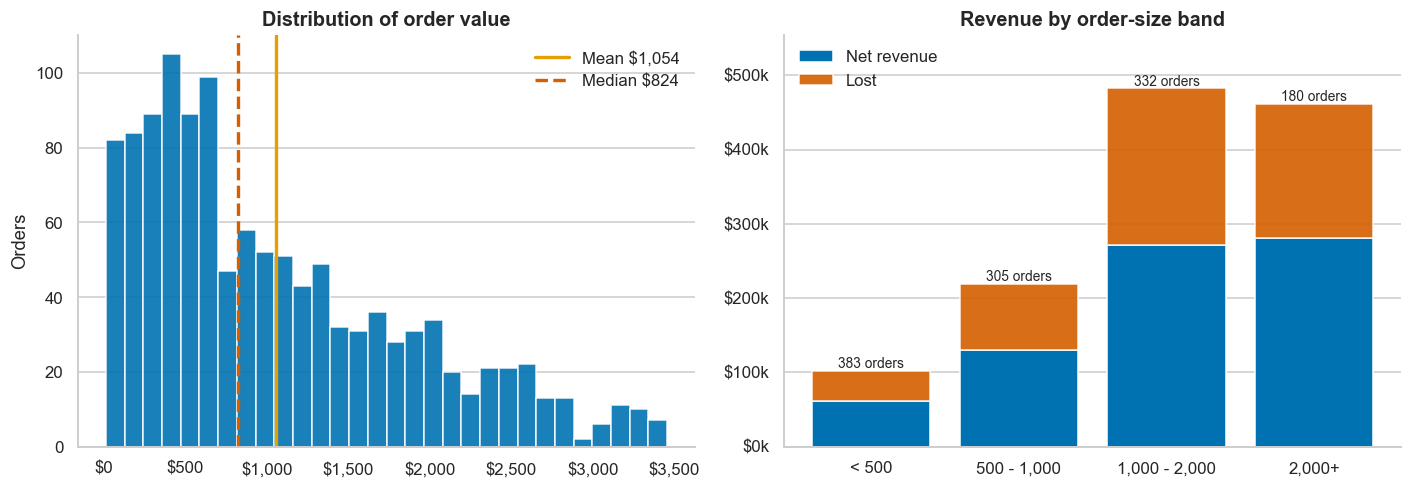

saved -> images\14_order_value_distribution.png


,OrderSizeBand,Orders,GrossSales,NetRevenue,LostRevenue,UnitsSold,LossRate,AvgOrderValue,NetShare
0,< 500,383,101696.90,60870.63,40826.27,486,0.428,265.527,0.082
1,"500 - 1,000",305,219504.99,130669.53,88835.46,449,0.403,719.688,0.175
2,"1,000 - 2,000",332,482242.95,272096.52,210146.43,667,0.425,1452.539,0.365
3,"2,000+",180,461317.12,281451.37,179865.75,492,0.383,2562.873,0.378


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(df["TotalPrice"], bins=30, color=NET, alpha=.9, edgecolor="white")
axes[0].axvline(df["TotalPrice"].mean(), color=ACCENT, lw=2.2, label=f"Mean ${df['TotalPrice'].mean():,.0f}")
axes[0].axvline(df["TotalPrice"].median(), color=LOST, lw=2.2, ls="--", label=f"Median ${df['TotalPrice'].median():,.0f}")
axes[0].xaxis.set_major_formatter(money); axes[0].set_title("Distribution of order value"); axes[0].set_ylabel("Orders"); axes[0].legend(frameon=False)
band = group_summary(df, "OrderSizeBand")
ax = axes[1]
ax.bar(band["OrderSizeBand"].astype(str), band["NetRevenue"], color=NET, label="Net revenue")
ax.bar(band["OrderSizeBand"].astype(str), band["LostRevenue"], bottom=band["NetRevenue"], color=LOST, alpha=.9, label="Lost")
for i, r in band.iterrows():
    ax.text(i, r["NetRevenue"]+r["LostRevenue"]+4000, f"{int(r['Orders'])} orders", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(money_k); ax.set_title("Revenue by order-size band"); ax.legend(frameon=False, loc="upper left")
ax.set_ylim(0, (band["NetRevenue"]+band["LostRevenue"]).max()*1.15)
fig.tight_layout()
save(fig, "14_order_value_distribution")
band.round(3)

In [20]:
# Large orders flagged by Project 1's IQR rule - kept in the data, listed here for transparency
q1, q3 = df["TotalPrice"].quantile([.25, .75]); fence = q3 + 1.5*(q3-q1)
big = df[df["TotalPrice"] > fence][["OrderID","Date","Product","Quantity","UnitPrice","TotalPrice","OrderStatus"]]
print(f"IQR upper fence = ${fence:,.2f}; {len(big)} large orders kept (not capped):")
big

IQR upper fence = $3,330.41; 8 large orders kept (not capped):


,OrderID,Date,Product,Quantity,UnitPrice,TotalPrice,OrderStatus
107,ORD200107,2023-03-27,Printer,5,670.75,3353.75,Shipped
326,ORD200326,2024-07-01,Laptop,5,670.48,3352.40,Returned
328,ORD200328,2023-02-28,Tablet,5,674.04,3370.20,Cancelled
469,ORD200469,2023-11-26,Chair,5,676.98,3384.90,Cancelled
632,ORD200632,2023-05-02,Laptop,5,678.16,3390.80,Delivered
789,ORD200789,2023-08-17,Tablet,5,691.28,3456.40,Delivered
1065,ORD201065,2023-10-30,Printer,5,666.80,3334.00,Delivered
1122,ORD201122,2023-06-07,Monitor,5,678.19,3390.95,Returned


## 10. Key findings (computed, not typed)

In [21]:
prod = group_summary(df, "Product").sort_values("NetRevenue", ascending=False)
ref = group_summary(df, "ReferralSource").sort_values("NetRevenue", ascending=False)
pay = group_summary(df, "PaymentMethod").sort_values("NetRevenue", ascending=False)
cp = group_summary(df, "CouponCode")
dow = group_summary(df, "DayName")
h1 = h1_comparison(df).set_index("Year")
tests = {d: chi_square_loss(df, d)[1] for d in ["Product","PaymentMethod","ReferralSource","CouponCode","DayName","Year"]}

coupon_yes, coupon_no = df[df["HasCoupon"]], df[~df["HasCoupon"]]
findings = {
    "headline": K,
    "top_product_net": [prod.iloc[0]["Product"], float(prod.iloc[0]["NetRevenue"])],
    "bottom_product_net": [prod.iloc[-1]["Product"], float(prod.iloc[-1]["NetRevenue"])],
    "top_referral_net": [ref.iloc[0]["ReferralSource"], float(ref.iloc[0]["NetRevenue"])],
    "top_payment_net": [pay.iloc[0]["PaymentMethod"], float(pay.iloc[0]["NetRevenue"])],
    "h1_gross": {int(y): float(v) for y, v in h1["GrossSales"].items()},
    "h1_net": {int(y): float(v) for y, v in h1["NetRevenue"].items()},
    "h1_gross_change_2024": float(h1.loc[2024, "GrossSales"]/h1.loc[2023, "GrossSales"]-1),
    "h1_gross_change_2025": float(h1.loc[2025, "GrossSales"]/h1.loc[2024, "GrossSales"]-1),
    "h1_net_change_2025": float(h1.loc[2025, "NetRevenue"]/h1.loc[2024, "NetRevenue"]-1),
    "h1_loss_rate_orders": {int(y): float(df[(df.Year == y) & (df.Month <= 6)]["IsLost"].mean()) for y in (2023, 2024, 2025)},
    "h1_orders": {int(y): int(v) for y, v in h1["Orders"].items()},
    "h1_aov": {int(y): float(h1.loc[y, "GrossSales"]/h1.loc[y, "Orders"]) for y in h1.index},
    "share_of_orders_1000_plus": float((df.TotalPrice >= 1000).mean()),
    "aov_with_coupon": float(coupon_yes["TotalPrice"].mean()), "aov_no_coupon": float(coupon_no["TotalPrice"].mean()),
    "loss_rate_with_coupon": float(coupon_yes["IsLost"].mean()), "loss_rate_no_coupon": float(coupon_no["IsLost"].mean()),
    "chi_square_p_values_loss_rate": {k: round(v, 4) for k, v in tests.items()},
    "share_of_net_from_orders_over_1000": float(df.loc[df.TotalPrice >= 1000, "NetRevenue"].sum()/df["NetRevenue"].sum()),
}
for k, v in findings.items():
    print(f"{k}: {v}")

headline: {'orders': 1200, 'gross': 1264761.96, 'net': 745088.05, 'lost': 519673.91000000003, 'units': 2094, 'aov_gross': 1053.9683, 'aov_net': 1059.8692034139403, 'loss_rate': 0.4141666666666667, 'cancel_rate': 0.20833333333333334, 'return_rate': 0.20583333333333334, 'customers': 1189, 'coupon_share': 0.7425}
top_product_net: ['Printer', 120998.36]
bottom_product_net: ['Phone', 94534.93]
top_referral_net: ['Instagram', 175505.5]
top_payment_net: ['Online', 170273.44]
h1_gross: {2023: 286501.52, 2024: 257059.34, 2025: 231882.85}
h1_net: {2023: 159930.12, 2024: 157461.74, 2025: 114200.39}
h1_gross_change_2024: -0.102764480970293
h1_gross_change_2025: -0.09794038217012457
h1_net_change_2025: -0.2747419785911167
h1_loss_rate_orders: {2023: 0.44841269841269843, 2024: 0.4008438818565401, 2025: 0.4675324675324675}
h1_orders: {2023: 252, 2024: 237, 2025: 231}
h1_aov: {2023: 1136.9107936507937, 2024: 1084.6385654008438, 2025: 1003.8218614718616}
share_of_orders_1000_plus: 0.4266666666666667
ao

In [22]:
# Persist machine-readable outputs for the Streamlit app / report
(OUT_DIR / "summary_metrics.json").write_text(json.dumps(findings, indent=2, default=str))
for name, t in {"by_product": prod, "by_referral": ref, "by_payment": pay, "by_coupon": cp, "by_weekday": dow,
                "monthly": monthly_summary(df), "h1_comparison": h1_comparison(df)}.items():
    t.to_csv(OUT_DIR / f"summary_{name}.csv", index=False)
print(sorted(p.name for p in OUT_DIR.iterdir()))
print(len(list(IMG_DIR.glob('*.png'))), "images saved")

['summary_by_coupon.csv', 'summary_by_payment.csv', 'summary_by_product.csv', 'summary_by_referral.csv', 'summary_by_weekday.csv', 'summary_h1_comparison.csv', 'summary_metrics.json', 'summary_monthly.csv']
15 images saved


## 11. Conclusions

1. **Sales are drifting down on a like-for-like basis.** Jan–Jun gross sales fell about 10% from H1 2023 to H1 2024 and about 10% again to H1 2025. Both levers contribute: orders fell from 252 to 237 to 231, and average order value fell from about $1,137 to $1,085 to $1,004 (the AOV drop is the larger driver in 2025). H1 2025 *net* revenue is down about 27% on H1 2024 because a higher share of orders was lost (46.8% vs 40.1%), although that year-to-year change in loss rate is not statistically significant (p = 0.16).
2. **Roughly four in ten orders never turn into revenue** (cancelled or returned), which is the single largest lever in the dataset. About $520k of the $1.26M gross value was lost.
3. **No segment is a statistically proven problem.** Product, payment method, referral source, coupon code and weekday show different loss rates, but none of the chi-square tests is significant at 5% (Section 5.1). Treat the gaps (e.g. *Online* payments and *Instagram* referrals with lower loss rates) as leads to monitor, not conclusions.
4. **Revenue is spread evenly across the seven products** — no product dominates, so there is no single-product dependency risk, but also no clear star to scale.
5. **Orders of $1,000+ generate about 74% of net revenue** from about 43% of orders (Section 9), so large-basket orders are where retention and fulfilment effort pays off most.
6. **Data caveats:** 1,189 unique customers across 1,200 orders means repeat-customer analysis is not meaningful; "Pending" orders are counted in net revenue and could still be cancelled.